In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/mlp-term-1-2026-kaggle-assignment-1/sample_submission.csv
/kaggle/input/competitions/mlp-term-1-2026-kaggle-assignment-1/train.csv
/kaggle/input/competitions/mlp-term-1-2026-kaggle-assignment-1/test.csv
/kaggle/input/datasets/yashjadhav24f1002856/taxi-dataset/train.csv
/kaggle/input/datasets/yashjadhav24f1002856/taxi-dataset/test.csv


In [2]:
df=pd.read_csv('/kaggle/input/datasets/yashjadhav24f1002856/taxi-dataset/train.csv')

In [3]:
df.describe()

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,extra,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
count,10000.000000,9634.000000,10000.000000,9634.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,9634.000000,9634.000000
mean,0.729100,1.357276,3.679527,1.450695,132.710800,132.33240,1.940950,6.094658,0.664425,0.979490,29.740157,2.238426,0.161122
std,0.444672,0.883676,4.905798,5.988978,75.789597,75.95944,1.945885,4.438894,2.441070,0.200076,26.256398,0.834189,0.512859
min,0.000000,0.000000,0.000000,1.000000,1.000000,1.00000,-7.500000,0.000713,-26.550000,-1.000000,-129.300000,-2.500000,-1.750000
25%,0.000000,1.000000,1.070000,1.000000,67.000000,68.00000,0.000000,3.466789,0.000000,1.000000,16.300000,2.500000,0.000000
50%,1.000000,1.000000,1.820000,1.000000,133.000000,132.00000,1.750000,5.208233,0.000000,1.000000,21.360000,2.500000,0.000000
75%,1.000000,1.000000,3.630000,1.000000,198.000000,199.00000,2.500000,7.455228,0.000000,1.000000,31.800000,2.500000,0.000000
max,2.000000,6.000000,71.940000,99.000000,264.000000,264.00000,11.750000,84.032617,32.050000,1.000000,551.000000,2.500000,1.750000


In [4]:
print(df.dtypes)
print(df.isnull().sum())

VendorID                   int64
tpep_pickup_datetime      object
tpep_dropoff_datetime     object
passenger_count          float64
trip_distance            float64
RatecodeID               float64
store_and_fwd_flag        object
PULocationID               int64
DOLocationID               int64
payment_type              object
extra                    float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
dtype: object
VendorID                   0
tpep_pickup_datetime       0
tpep_dropoff_datetime      0
passenger_count          366
trip_distance              0
RatecodeID               366
store_and_fwd_flag       366
PULocationID               0
DOLocationID               0
payment_type               0
extra                      0
tip_amount                 0
tolls_amount               0
improvement_surcharge      0
total_amount       

In [5]:
null_mask = df[['passenger_count', 'RatecodeID', 'store_and_fwd_flag', 
                'congestion_surcharge', 'Airport_fee']].isnull()
print(null_mask.all(axis=1).sum())

366


In [6]:
df[df['passenger_count'].isnull()]['VendorID'].value_counts()

VendorID
1    296
0     69
2      1
Name: count, dtype: int64

since 366 is just 3.6% of data we will drop it

In [7]:
df = df.dropna(subset=['passenger_count', 'RatecodeID', 
                        'congestion_surcharge', 'Airport_fee'])

df = df.drop(columns=['store_and_fwd_flag'])#Completely useless!
print(df.shape)
print(df.isnull().sum().sum())

(9634, 16)
0


In [8]:
df.describe()

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,extra,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
count,9634.000000,9634.000000,9634.000000,9634.000000,9634.000000,9634.000000,9634.000000,9634.000000,9634.000000,9634.000000,9634.000000,9634.000000,9634.000000
mean,0.725867,1.357276,3.622093,1.450695,132.645941,132.478098,2.006410,6.091081,0.637529,0.978856,29.523995,2.238426,0.161122
std,0.446100,0.883676,4.890997,5.988978,75.916477,76.036213,1.946598,4.444998,2.377398,0.203566,26.379777,0.834189,0.512859
min,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,-7.500000,0.000713,-26.550000,-1.000000,-129.300000,-2.500000,-1.750000
25%,0.000000,1.000000,1.060000,1.000000,67.000000,68.000000,0.000000,3.471558,0.000000,1.000000,16.100000,2.500000,0.000000
50%,1.000000,1.000000,1.800000,1.000000,132.000000,133.000000,2.500000,5.204543,0.000000,1.000000,21.200000,2.500000,0.000000
75%,1.000000,1.000000,3.500000,1.000000,198.000000,199.000000,2.500000,7.442048,0.000000,1.000000,31.150000,2.500000,0.000000
max,1.000000,6.000000,71.940000,99.000000,264.000000,264.000000,11.750000,84.032617,32.050000,1.000000,551.000000,2.500000,1.750000


In [9]:
print(f"Before: {len(df)} rows")

df = df.drop_duplicates()

print(f"After:  {len(df)} rows")
print(f"Removed: {9634 - len(df)} duplicate rows")

Before: 9634 rows
After:  9634 rows
Removed: 0 duplicate rows


In [10]:
# Converting to datetime 
df['tpep_pickup_datetime']  = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])

df['trip_duration_min'] = (
    df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']
).dt.total_seconds() / 60
#found the duration of trip
print(df['trip_duration_min'].describe())


count    9634.000000
mean       16.884105
std        59.055616
min      -114.250000
25%       -19.095833
50%        15.541667
75%        51.175000
max      1483.583333
Name: trip_duration_min, dtype: float64


Negative duration and 1483 minutes is wild!

In [11]:
print(df.dtypes)

VendorID                          int64
tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
PULocationID                      int64
DOLocationID                      int64
payment_type                     object
extra                           float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
trip_duration_min               float64
dtype: object


In [12]:
df = df[
    (df['trip_duration_min'] > 1)    &  
    (df['trip_duration_min'] < 600)     
]
df = df[df['passenger_count'] >= 1]
df = df[df['RatecodeID'] <= 6]
print(df.describe())  

          VendorID           tpep_pickup_datetime  \
count  5695.000000                           5695   
mean      0.745215  2023-06-29 20:05:36.942054400   
min       0.000000            2023-06-28 15:31:32   
25%       0.000000     2023-06-29 08:24:55.500000   
50%       1.000000            2023-06-29 19:00:31   
75%       1.000000     2023-06-30 12:33:11.500000   
max       1.000000            2023-07-01 00:48:35   
std       0.435778                            NaN   

               tpep_dropoff_datetime  passenger_count  trip_distance  \
count                           5695      5695.000000    5695.000000   
mean   2023-06-29 20:54:03.713256960         1.399122       4.218809   
min              2023-06-28 15:50:53         1.000000       0.000000   
25%       2023-06-29 09:09:53.500000         1.000000       1.130000   
50%              2023-06-29 19:51:00         1.000000       2.000000   
75%              2023-06-30 13:23:46         1.000000       4.210000   
max              2

NOW REMOVING OUTLIER

In [13]:
df = df[df['total_amount'] <= 300]
print(df['total_amount'].describe())

count    5691.000000
mean       32.561961
std        27.984791
min      -103.800000
25%        16.800000
50%        22.700000
75%        34.900000
max       294.660000
Name: total_amount, dtype: float64


In [14]:
print(f"Negative fares: {(df['total_amount'] < 0).sum()}")
print(f"Zero fares:     {(df['total_amount'] == 0).sum()}")
print(f"Under $2.50:    {(df['total_amount'] < 2.50).sum()}")

# See what the negative rows look like
print(df[df['total_amount'] < 0][['total_amount', 'trip_distance', 'trip_duration_min']].head(10))

Negative fares: 58
Zero fares:     1
Under $2.50:    59
      total_amount  trip_distance  trip_duration_min
115          -9.50           0.02          36.033333
116          -8.70           0.19          29.216667
1237         -7.25           0.02          23.333333
1400       -103.80          24.61          47.500000
1544        -82.30          19.86          50.850000
1610        -19.90           0.65           1.150000
2228        -31.20           1.36          19.533333
2369        -16.10           0.83          47.600000
2645        -24.80           2.77           9.100000
2973        -40.60           1.13         133.233333


In [15]:
df = df[df['total_amount'] >= 2.50]
print(f"95th percentile: ${df['total_amount'].quantile(0.95):.2f}")
print(f"99th percentile: ${df['total_amount'].quantile(0.99):.2f}")
print(f"Max:             ${df['total_amount'].max():.2f}")

95th percentile: $95.41
99th percentile: $128.55
Max:             $294.66


In [16]:
# Extract time-based features from pickup datetime
df['hour']        = df['tpep_pickup_datetime'].dt.hour
df['day_of_week'] = df['tpep_pickup_datetime'].dt.dayofweek  # 0=Monday, 6=Sunday
df['month']       = df['tpep_pickup_datetime'].dt.month
df['is_weekend']  = df['day_of_week'].isin([5, 6]).astype(int)

# trip_duration_min already created earlier

# Verify
print(df[['hour', 'day_of_week', 'month', 'is_weekend', 'trip_duration_min']].head())
print(df.shape)

    hour  day_of_week  month  is_weekend  trip_duration_min
0     17            2      6           0          50.433333
5     15            4      6           0         133.400000
6      7            3      6           0          24.650000
7     16            4      6           0          68.800000
15    23            2      6           0          44.333333
(5632, 21)


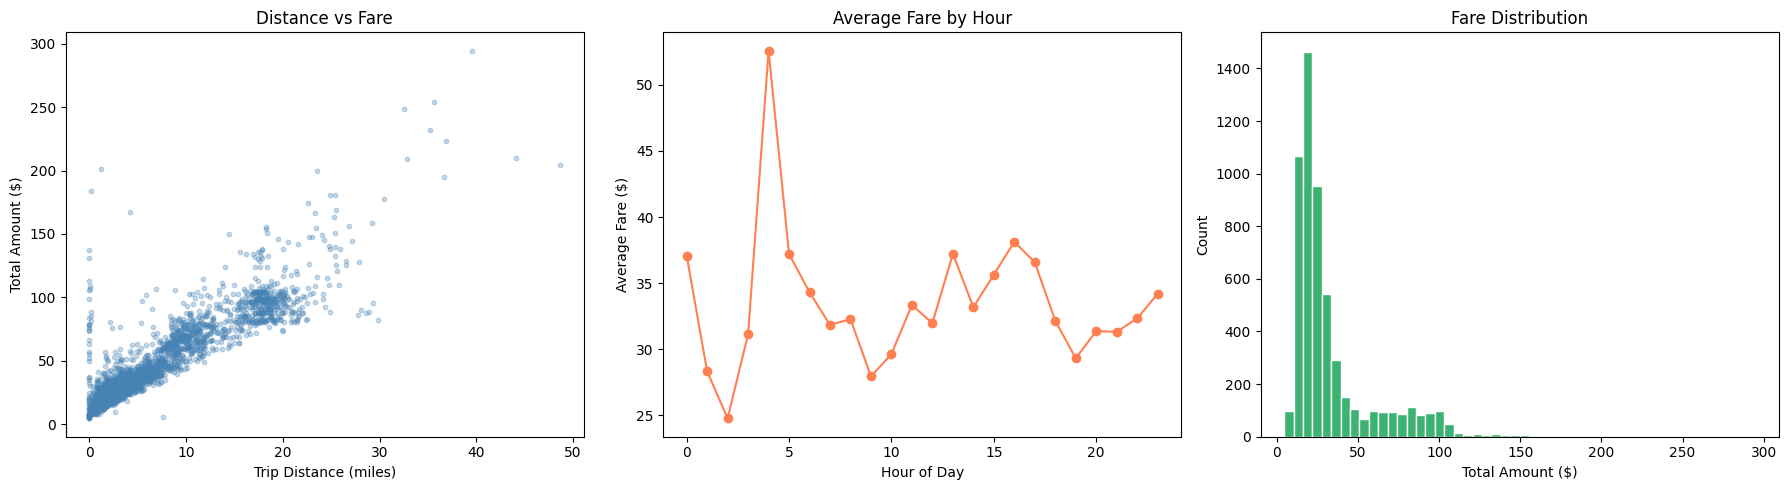

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Viz 1: Trip distance vs Total amount 
axes[0].scatter(df['trip_distance'], df['total_amount'], 
                alpha=0.3, s=10, color='steelblue')
axes[0].set_xlabel('Trip Distance (miles)')
axes[0].set_ylabel('Total Amount ($)')
axes[0].set_title('Distance vs Fare')

# Viz 2: Average fare by hour of day 
hourly = df.groupby('hour')['total_amount'].mean()
axes[1].plot(hourly.index, hourly.values, marker='o', color='coral')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Average Fare ($)')
axes[1].set_title('Average Fare by Hour')

# 3: Fare distribution 
axes[2].hist(df['total_amount'], bins=50, color='mediumseagreen', edgecolor='white')
axes[2].set_xlabel('Total Amount ($)')
axes[2].set_ylabel('Count')
axes[2].set_title('Fare Distribution')

plt.tight_layout()
plt.savefig('taxi_visualizations.png', dpi=150)
plt.show()

lets start scaling and encoding

In [18]:
print(df.columns.tolist())

['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'extra', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'trip_duration_min', 'hour', 'day_of_week', 'month', 'is_weekend']


In [19]:
from sklearn.preprocessing import StandardScaler

numerical_cols = ['trip_distance', 'trip_duration_min', 
                  'passenger_count', 'hour', 'day_of_week']

scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

In [20]:
#  VendorID, RatecodeID, payment_type are already encoded

# 1. Drop datetime and location columns
drop_cols = ['tpep_pickup_datetime', 'tpep_dropoff_datetime',
             'PULocationID', 'DOLocationID']

df = df.drop(columns=drop_cols, errors='ignore')

# Scale numerical columns
from sklearn.preprocessing import StandardScaler

numerical_cols = ['trip_distance', 'trip_duration_min', 
                  'passenger_count', 'hour', 'day_of_week', 'month',
                  'extra', 'tip_amount', 'tolls_amount', 
                  'improvement_surcharge', 'congestion_surcharge', 'Airport_fee']

scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

df = df.drop(columns=['tip_amount', 'improvement_surcharge'])#already in total fare


print(df.shape)
print(df.columns.tolist())

(5632, 15)
['VendorID', 'passenger_count', 'trip_distance', 'RatecodeID', 'payment_type', 'extra', 'tolls_amount', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'trip_duration_min', 'hour', 'day_of_week', 'month', 'is_weekend']


NOW we will split the data

In [21]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['total_amount'])
y = df['total_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set:   {X_train.shape}")
print(f"Test set:       {X_test.shape}")

Training set:   (4505, 14)
Test set:       (1127, 14)


In [22]:
# Re-encode any remaining categorical columns in X_train and X_test
X_train = pd.get_dummies(X_train, drop_first=True)
X_test  = pd.get_dummies(X_test, drop_first=True)

# Align columns — test must match train exactly
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(X_train.dtypes.value_counts())
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")

float64    11
bool        3
int64       2
Name: count, dtype: int64
X_train: (4505, 16)
X_test:  (1127, 16)


In [23]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Define all 7 models
models = {
    'Linear Regression' : LinearRegression(),
    'Ridge'             : Ridge(),
    'Lasso'             : Lasso(),
    'Decision Tree'     : DecisionTreeRegressor(random_state=42),
    'Random Forest'     : RandomForestRegressor(random_state=42),
    'KNN'               : KNeighborsRegressor(),
    'XGBoost'           : XGBRegressor(random_state=42)
}

# Train and evaluate each
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
   
    y_pred = model.predict(X_test)
    
    # And metrics use y_test
    results[name] = {
        'R2'   : round(r2_score(y_test, y_pred), 4),
        'MAE'  : round(mean_absolute_error(y_test, y_pred), 4),
        'RMSE' : round(np.sqrt(mean_squared_error(y_test, y_pred)), 4)
    }

# Print results table
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values('R2', ascending=False)
print(results_df)

                       R2     MAE     RMSE
Random Forest      0.9295  3.5718   7.4673
XGBoost            0.9261  3.6868   7.6441
Decision Tree      0.9077  4.6225   8.5448
Linear Regression  0.8925  4.7199   9.2184
Ridge              0.8925  4.7198   9.2189
Lasso              0.8691  5.0681  10.1736
KNN                0.8691  5.6868  10.1730


NOW we hyperparamtise

In [24]:
from sklearn.model_selection import GridSearchCV

# 1. Random Forest
rf_params = {
    'n_estimators'    : [100, 200, 300],
    'max_depth'       : [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(RandomForestRegressor(random_state=42), 
                       rf_params, cv=5, scoring='r2', n_jobs=-1)
rf_grid.fit(X_train, y_train)
print(f"Best RF params: {rf_grid.best_params_}")
print(f"Best RF R2:     {rf_grid.best_score_:.4f}")

Best RF params: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 300}
Best RF R2:     0.9283


In [25]:
#  2. XGBoost 
xgb_params = {
    'n_estimators'  : [100, 200, 300],
    'max_depth'     : [3, 5, 7],
    'learning_rate' : [0.01, 0.1, 0.2]
}

xgb_grid = GridSearchCV(XGBRegressor(random_state=42),
                        xgb_params, cv=5, scoring='r2', n_jobs=-1)
xgb_grid.fit(X_train, y_train)
print(f"Best XGB params: {xgb_grid.best_params_}")
print(f"Best XGB R2:     {xgb_grid.best_score_:.4f}")

Best XGB params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Best XGB R2:     0.9222


In [26]:
# 3. Linear Regression 
lr_params = {
    'fit_intercept' : [True, False],
    'positive'      : [True, False]
}

lr_grid = GridSearchCV(LinearRegression(),
                       lr_params, cv=5, scoring='r2', n_jobs=-1)
lr_grid.fit(X_train, y_train)
print(f"Best LR params: {lr_grid.best_params_}")
print(f"Best LR R2:     {lr_grid.best_score_:.4f}")

Best LR params: {'fit_intercept': False, 'positive': False}
Best LR R2:     0.9049


In [27]:
# ── Final Model Comparison 
# Best tuned models
rf_best  = rf_grid.best_estimator_
xgb_best = xgb_grid.best_estimator_
lr_best  = lr_grid.best_estimator_

# All models including tuned versions
all_models = {
    # Base models
    'Linear Regression'    : LinearRegression(),
    'Ridge'                : Ridge(),
    'Lasso'                : Lasso(),
    'Decision Tree'        : DecisionTreeRegressor(random_state=42),
    'Random Forest'        : RandomForestRegressor(random_state=42),
    'KNN'                  : KNeighborsRegressor(),
    'XGBoost'              : XGBRegressor(random_state=42),
    # Tuned models
    'Random Forest (Tuned)': rf_best,
    'XGBoost (Tuned)'      : xgb_best,
    'Linear Reg (Tuned)'   : lr_best
}

# Evaluate all
final_results = {}

for name, model in all_models.items():
    if 'Tuned' not in name:
        model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    final_results[name] = {
        'R2'   : round(r2_score(y_test, y_pred), 4),
        'MAE'  : round(mean_absolute_error(y_test, y_pred), 4),
        'RMSE' : round(np.sqrt(mean_squared_error(y_test, y_pred)), 4)
    }

# Print sorted by R2
final_df = pd.DataFrame(final_results).T
final_df = final_df.sort_values('R2', ascending=False)
print(final_df)

                           R2     MAE     RMSE
Random Forest (Tuned)  0.9303  3.5266   7.4226
Random Forest          0.9295  3.5718   7.4673
XGBoost (Tuned)        0.9279  3.4242   7.5529
XGBoost                0.9261  3.6868   7.6441
Decision Tree          0.9077  4.6225   8.5448
Linear Regression      0.8925  4.7199   9.2184
Ridge                  0.8925  4.7198   9.2189
Linear Reg (Tuned)     0.8925  4.7199   9.2184
KNN                    0.8691  5.6868  10.1730
Lasso                  0.8691  5.0681  10.1736


In [28]:
test_df = pd.read_csv('/kaggle/input/datasets/yashjadhav24f1002856/taxi-dataset/test.csv')
print(test_df.columns.tolist())
print(test_df.shape)

['id', 'VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'extra', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'congestion_surcharge', 'Airport_fee']
(1500, 17)


In [29]:
# Reload completely fresh — bypass df entirely
train_raw = pd.read_csv('/kaggle/input/datasets/yashjadhav24f1002856/taxi-dataset/train.csv')

# Apply only cleaning — NO scaling
train_raw = train_raw.dropna(subset=['passenger_count', 'RatecodeID',
                                      'congestion_surcharge', 'Airport_fee'])
train_raw = train_raw.drop(columns=['store_and_fwd_flag'])
train_raw = train_raw.drop_duplicates()

train_raw['tpep_pickup_datetime']  = pd.to_datetime(train_raw['tpep_pickup_datetime'])
train_raw['tpep_dropoff_datetime'] = pd.to_datetime(train_raw['tpep_dropoff_datetime'])
train_raw['trip_duration_min'] = (
    train_raw['tpep_dropoff_datetime'] - train_raw['tpep_pickup_datetime']
).dt.total_seconds() / 60

train_raw['hour']        = train_raw['tpep_pickup_datetime'].dt.hour
train_raw['day_of_week'] = train_raw['tpep_pickup_datetime'].dt.dayofweek
train_raw['month']       = train_raw['tpep_pickup_datetime'].dt.month
train_raw['is_weekend']  = train_raw['day_of_week'].isin([5, 6]).astype(int)

# Apply filters
train_raw = train_raw[
    (train_raw['total_amount']      >= 2.50)  &
    (train_raw['total_amount']      <= 150)   &
    (train_raw['trip_distance']     > 0.1)    &
    (train_raw['passenger_count']   >= 1)     &
    (train_raw['passenger_count']   <= 6)     &
    (train_raw['RatecodeID']        <= 6)     &
    (train_raw['trip_duration_min'] > 1)      &
    (train_raw['trip_duration_min'] < 180)
]

# Drop unnecessary columns
train_raw = train_raw.drop(columns=['tpep_pickup_datetime', 'tpep_dropoff_datetime',
                                     'PULocationID', 'DOLocationID',
                                     'tip_amount', 'improvement_surcharge'])

# Encode
train_raw = pd.get_dummies(train_raw, 
                            columns=['VendorID', 'RatecodeID', 'payment_type'], 
                            drop_first=True)

print(f"Shape: {train_raw.shape}")
print(f"trip_distance mean: {train_raw['trip_distance'].mean():.3f}")  # should be ~3-4 miles

Shape: (5540, 20)
trip_distance mean: 4.135


In [30]:
numerical_cols = ['trip_distance', 'trip_duration_min', 
                  'passenger_count', 'hour', 'day_of_week', 'month',
                  'extra', 'tolls_amount', 'congestion_surcharge', 'Airport_fee']

# Split
X = train_raw.drop(columns=['total_amount'])
y = train_raw['total_amount']

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Scale
scaler_final = StandardScaler()
X_train_raw[numerical_cols] = scaler_final.fit_transform(X_train_raw[numerical_cols])
X_test_raw[numerical_cols]  = scaler_final.transform(X_test_raw[numerical_cols])

# Train
rf_final = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_final.fit(X_train_raw, y_train_raw)
print(f"Local R2: {r2_score(y_test_raw, rf_final.predict(X_test_raw)):.4f}")

# Prepare test
test_df = pd.read_csv('/kaggle/input/datasets/yashjadhav24f1002856/taxi-dataset/test.csv')
test_ids = test_df['id']
test_df = test_df.fillna(0)

test_df['tpep_pickup_datetime']  = pd.to_datetime(test_df['tpep_pickup_datetime'])
test_df['tpep_dropoff_datetime'] = pd.to_datetime(test_df['tpep_dropoff_datetime'])
test_df['trip_duration_min'] = (
    test_df['tpep_dropoff_datetime'] - test_df['tpep_pickup_datetime']
).dt.total_seconds() / 60
test_df['hour']        = test_df['tpep_pickup_datetime'].dt.hour
test_df['day_of_week'] = test_df['tpep_pickup_datetime'].dt.dayofweek
test_df['month']       = test_df['tpep_pickup_datetime'].dt.month
test_df['is_weekend']  = test_df['day_of_week'].isin([5, 6]).astype(int)

test_df = test_df.drop(columns=['id', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
                                 'PULocationID', 'DOLocationID', 'store_and_fwd_flag',
                                 'tip_amount', 'improvement_surcharge'])

test_df['VendorID']     = test_df['VendorID'].astype(int)
test_df['RatecodeID']   = test_df['RatecodeID'].astype(int)
test_df['payment_type'] = test_df['payment_type'].astype(str)

test_df = pd.get_dummies(test_df, columns=['VendorID', 'RatecodeID', 'payment_type'],
                          drop_first=True)

X_test_final = test_df.reindex(columns=X_train_raw.columns, fill_value=0)
X_test_final[numerical_cols] = scaler_final.transform(X_test_final[numerical_cols])

print(f"Test mean:  {X_test_final['trip_distance'].mean():.3f}")
print(f"Train mean: {X_train_raw['trip_distance'].mean():.3f}")

# Submit
predictions = rf_final.predict(X_test_final)
print(f"Prediction mean: ${predictions.mean():.2f}")

submission = pd.DataFrame({
    'id'           : test_ids.values,
    'total_amount' : predictions
})
submission.to_csv('submission4.csv', index=False)
print("Done!")

Local R2: 0.9571
Test mean:  -0.058
Train mean: -0.000
Prediction mean: $30.55
Done!
